# Market Regime Detection with Hidden Markov Models

Markets alternate between calm, normal and turbulent phases. This notebook detects these **regimes** in the S&P 500 (SPY) with
Gaussian Hidden Markov Models, then asks a precise question: **does knowing the current regime improve a portfolio, compared with
simple rules that need no model?**

**Design**
- **Out-of-sample by construction.** Walk-forward evaluation from **2007**: every year the HMM is refitted on all data available
  before January 1st and then run forward through that year. The 2008 crisis, 2020 and 2022 are all out of sample.
- **No look-ahead.** Strategies only use *filtered* probabilities $P(s_t \mid x_1,\dots,x_t)$, and the position decided at the
  close of day $t$ is held on day $t+1$.
- **Two feature sets**:
  - *Vol*: daily return and 10-day realised volatility;
  - *Vol+Trend+VIX*: the same plus the distance to the 200-day moving average and the VIX (implied volatility).

  Each is tested with 3 and 4 regimes.
- **Realistic accounting.** Cash earns the 13-week T-bill rate, leverage pays T-bill + a spread, and every trade pays a cost.
  Sharpe ratios use excess returns.
- **Fair benchmarks**, all without an HMM: buy & hold; trailing-volatility targeting; a 200-day trend rule; and, for each
  strategy, a portfolio with the **same average exposure held constant**.
- **Statistical significance.** Block-bootstrap confidence intervals for Sharpe-ratio differences.

In [38]:
# Packages not always preinstalled on Kaggle / Colab. Without hmmlearn, a NumPy HMM is used (slower);
# without yfinance (or without internet), a synthetic dataset is used so the notebook still runs.
import importlib.util, subprocess, sys
for pkg in ["yfinance", "hmmlearn"]:
    if importlib.util.find_spec(pkg) is None:
        try:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--retries", "1", "--timeout", "15", pkg],
                           check=True)
        except Exception as e:
            print(f"Could not install {pkg}: {e}")

In [39]:
import time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import multivariate_normal
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")
try:
    from hmmlearn import hmm as hmmlearn_hmm
except ImportError:
    hmmlearn_hmm = None

TICKER      = "SPY"
VIX_TICKER  = "^VIX"            # implied volatility index
RF_TICKER   = "^IRX"            # 13-week T-bill yield (in %)
START       = "2000-01-01"
END         = None
TEST_START  = "2007-01-01"      # walk-forward evaluation starts here (first fit uses 2000-2006)
REFIT_EVERY_YEARS = 1

VOL_WINDOW   = 10
TREND_WINDOW = 200
FEATURE_SETS = {
    "Vol":           ["ret", "log_vol"],
    "Vol+Trend+VIX": ["ret", "log_vol", "trend", "log_vix"],
}
CONFIGS = [("Vol", 3), ("Vol", 4), ("Vol+Trend+VIX", 3), ("Vol+Trend+VIX", 4)]
MAIN_CONFIG = ("Vol+Trend+VIX", 4)     # fixed BEFORE looking at test results; analysed in detail in section 7
STATE_CANDIDATES = [2, 3, 4]
N_INIT, WF_N_INIT = 5, 3               # EM restarts (model selection / each walk-forward refit)

EXIT_P, ENTER_P = 0.7, 0.3            # hysteresis: leave when P(turbulent) > 0.7, come back when < 0.3
TARGET_VOL      = 0.15                # annualised volatility target
MAX_LEVERAGE    = 1.5                 # cap on exposure for vol-targeting rules
BORROW_SPREAD   = 0.005               # annual spread over T-bill paid on borrowed money
COST_BPS        = 5                   # cost per unit of turnover, basis points
REBALANCE_BAND  = 0.10                # vol-targeting rules only trade when the target moves more than this

BOOT_N, BOOT_BLOCK = 2000, 21          # block bootstrap: resamples and block length (days)
TRADING_DAYS, SEED = 252, 42

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
print("HMM backend:", "hmmlearn" if hmmlearn_hmm else "NumPy (hmmlearn not installed; walk-forward will be slower)")

HMM backend: hmmlearn


## 1. Data

SPY (adjusted close), the VIX and the 13-week T-bill yield from Yahoo Finance. If the VIX cannot be downloaded, a proxy based on
realised volatility is used; if the T-bill yield is missing, cash earns 0 %. Without internet, the notebook switches to a
**synthetic** market generated from known regimes (clearly flagged), so every cell still runs.

In [40]:
TRUE_REGIME, SYNTHETIC, VIX_IS_PROXY = None, False, False

def yf_close(ticker):
    import yfinance as yf
    raw = yf.download(ticker, start=START, end=END, auto_adjust=True, progress=False)
    close = raw["Close"]
    if isinstance(close, pd.DataFrame):
        close = close.iloc[:, 0]
    close = close.dropna()
    close.index = pd.to_datetime(close.index).tz_localize(None)
    return close[~close.index.duplicated()].sort_index()

def simulate_market(n=6900, seed=SEED):
    # Synthetic SPY / VIX / T-bill from a 4-regime Markov chain (offline fallback only)
    global TRUE_REGIME
    rng = np.random.default_rng(seed)
    A = np.array([[0.985, 0.012, 0.002, 0.001],
                  [0.015, 0.970, 0.010, 0.005],
                  [0.010, 0.030, 0.950, 0.010],
                  [0.005, 0.010, 0.035, 0.950]])
    mu = np.array([0.0008, 0.0003, 0.0010, -0.0025])     # the 3rd regime is a volatile rebound
    sd = np.array([0.006, 0.010, 0.020, 0.030])
    s = np.zeros(n, dtype=int)
    for t in range(1, n):
        s[t] = rng.choice(4, p=A[s[t - 1]])
    r = rng.normal(mu[s], sd[s])
    idx = pd.bdate_range(START, periods=n)
    TRUE_REGIME = pd.Series(s, index=idx)
    px = pd.Series(100 * np.exp(np.cumsum(r)), index=idx)
    vix = pd.Series(100 * sd[s] * np.sqrt(TRADING_DAYS) * np.exp(rng.normal(0, 0.1, n)), index=idx).ewm(span=5).mean()
    irx = pd.Series(2 + np.sin(np.arange(n) / 900), index=idx)
    return px, vix, irx

try:
    px = yf_close(TICKER)
    if len(px) < 1000:
        raise ValueError(f"only {len(px)} rows")
    source = "Yahoo Finance"
except Exception as e:
    print(f"Download of {TICKER} failed ({type(e).__name__}: {e})")
    SYNTHETIC = True

if SYNTHETIC:
    px, vix, irx = simulate_market()
    source = "SYNTHETIC 4-regime simulation"
    print("WARNING: synthetic data. Results describe a simulated market, not SPY.")
else:
    try:
        vix = yf_close(VIX_TICKER)
    except Exception as e:
        print(f"VIX download failed ({e})"); vix = None
    try:
        irx = yf_close(RF_TICKER)
    except Exception as e:
        print(f"T-bill download failed ({e}); cash will earn 0 %"); irx = None

px = px.rename(TICKER)
if vix is None or len(vix) < 1000:
    VIX_IS_PROXY = True
    vix = 100 * np.log(px).diff().rolling(21).std() * np.sqrt(TRADING_DAYS)
    print("Using realised volatility as a VIX proxy.")
if irx is None or len(irx) < 1000:
    irx = pd.Series(0.0, index=px.index)

print(f"Source: {source}")
print(f"{TICKER}: {len(px):,} days from {px.index[0].date()} to {px.index[-1].date()} | "
      f"VIX {'proxy' if VIX_IS_PROXY else ('simulated' if SYNTHETIC else 'downloaded')} | T-bill mean {irx.mean():.2f} %")

Source: Yahoo Finance
SPY: 6,733 days from 2000-01-03 to 2026-10-09 | VIX downloaded | T-bill mean 1.92 %


## 2. Features

All features are known at the close of day $t$:

| Feature | Definition | Why |
|---|---|---|
| `ret` | daily log return | direction of the market |
| `log_vol` | log of 10-day realised volatility (annualised) | recent risk |
| `trend` | $\log P_t - \log \text{MA}_{200}(P)_t$ | separates falling markets from rebounds |
| `log_vix` | log of the VIX | market's *expected* volatility (forward-looking, unlike realised vol) |

Each walk-forward refit standardises the features with the statistics of its own training window only.

In [41]:
log_px = np.log(px)
log_ret = log_px.diff()
data = pd.DataFrame({
    "ret": log_ret,
    "log_vol": np.log(log_ret.rolling(VOL_WINDOW).std() * np.sqrt(TRADING_DAYS)),
    "trend": log_px - log_px.rolling(TREND_WINDOW).mean(),
    "log_vix": np.log(vix.reindex(px.index).ffill(limit=5)),
}).replace([np.inf, -np.inf], np.nan).dropna()

simple_ret = px.pct_change().reindex(data.index)
rf_daily = (irx.reindex(px.index).ffill() / 100 / TRADING_DAYS).reindex(data.index).fillna(0)
rf_earned = rf_daily.shift(1).fillna(0)          # rate known at yesterday's close, earned today

test_idx = data.index[data.index >= pd.Timestamp(TEST_START)]
EVAL_IDX = test_idx[1:]                           # first test day only sets the initial position
first_fit = data.index < pd.Timestamp(TEST_START)

print(f"Feature sample: {data.index[0].date()} to {data.index[-1].date()} ({len(data):,} days)")
print(f"First training window: {first_fit.sum():,} days | evaluation: {EVAL_IDX[0].date()} to {EVAL_IDX[-1].date()} "
      f"({len(EVAL_IDX):,} days, {len(EVAL_IDX) / TRADING_DAYS:.1f} years)")
data.describe().T.round(4)

Feature sample: 2000-10-16 to 2026-10-09 (6,534 days)
First training window: 1,560 days | evaluation: 2007-01-04 to 2026-10-09 (4,973 days, 19.7 years)


,count,mean,std,min,25%,50%,75%,max
ret,6534.0,0.0003,0.0120,-0.1159,-0.0044,0.0007,0.0059,0.1356
log_vol,6534.0,-2.0188,0.5629,-3.9091,-2.4156,-2.0404,-1.6661,0.1228
trend,6534.0,0.0318,0.0838,-0.4860,-0.0026,0.0518,0.0845,0.2015
log_vix,6534.0,2.9117,0.3556,2.2127,2.6383,2.8645,3.1338,4.4151


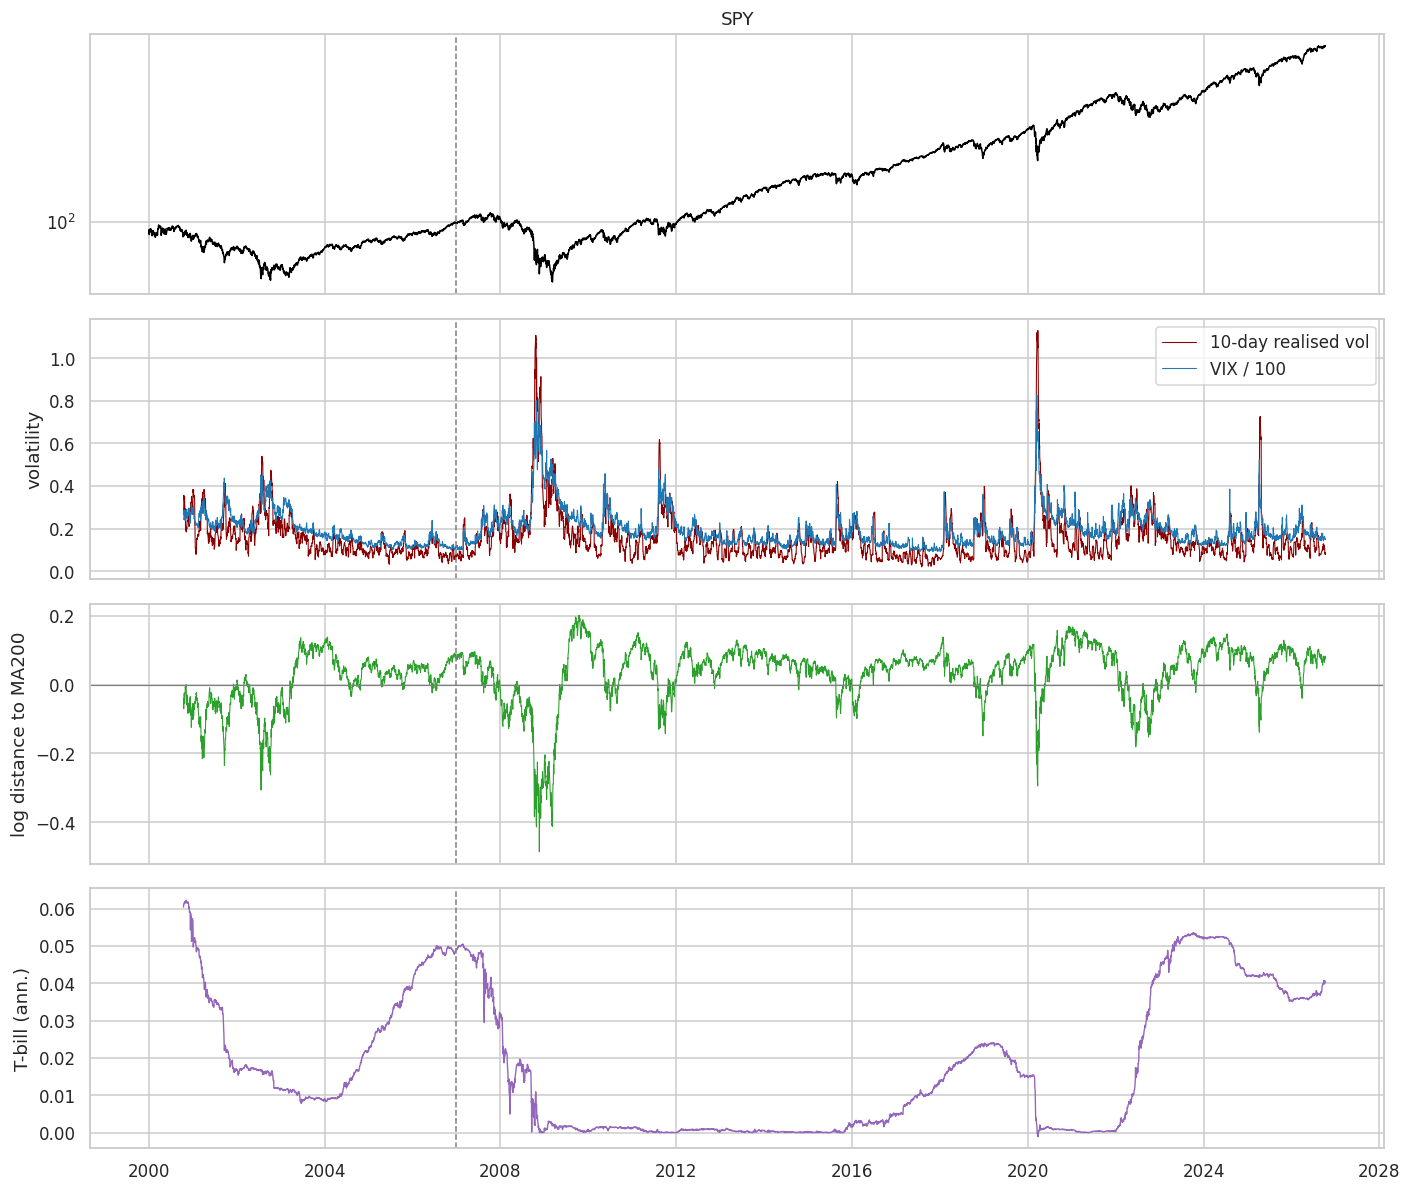

In [42]:
fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
axes[0].plot(px.index, px, color="black", lw=1); axes[0].set_yscale("log"); axes[0].set_title(TICKER)
axes[1].plot(data.index, np.exp(data["log_vol"]), color="darkred", lw=0.7, label=f"{VOL_WINDOW}-day realised vol")
axes[1].plot(data.index, np.exp(data["log_vix"]) / 100, color="tab:blue", lw=0.7, label="VIX / 100")
axes[1].legend(loc="upper right"); axes[1].set_ylabel("volatility")
axes[2].plot(data.index, data["trend"], color="tab:green", lw=0.7); axes[2].axhline(0, color="gray", lw=0.8)
axes[2].set_ylabel("log distance to MA200")
axes[3].plot(data.index, rf_daily * TRADING_DAYS, color="tab:purple", lw=0.9); axes[3].set_ylabel("T-bill (ann.)")
for ax in axes:
    ax.axvline(pd.Timestamp(TEST_START), color="gray", ls="--", lw=1)
plt.tight_layout(); plt.savefig(OUT / "01_data.png", bbox_inches="tight"); plt.show()

## 3. Gaussian Hidden Markov Model

The hidden regime $s_t$ follows a Markov chain with transition matrix $A_{ij} = P(s_t = j \mid s_{t-1} = i)$, and
$x_t \mid s_t = k \sim \mathcal{N}(\mu_k, \Sigma_k)$. Parameters are estimated by EM (Baum–Welch) with several random restarts.
The **filtered** probabilities come from the forward recursion
$\alpha_t(j) \propto \mathcal{N}(x_t;\mu_j,\Sigma_j)\sum_i \alpha_{t-1}(i)A_{ij}$, which never uses future data.

Parameters are estimated with `hmmlearn` when available (fast), otherwise with the NumPy Baum–Welch below. Filtering and
smoothing always use the NumPy code. States are sorted by mean volatility, so state 0 is always the calmest.

In [43]:
class GaussianHMM:
    # Gaussian HMM with full covariance matrices

    def __init__(self, n_states, n_init=5, n_iter=300, tol=1e-4, reg_covar=1e-4, random_state=0, backend="auto"):
        self.n_states, self.n_init, self.n_iter, self.tol = n_states, n_init, n_iter, tol
        self.reg_covar, self.random_state = reg_covar, random_state
        self.use_hmmlearn = backend == "hmmlearn" or (backend == "auto" and hmmlearn_hmm is not None)

    def _set(self, startprob, transmat, means, covars):
        self.startprob_ = np.asarray(startprob, float)
        self.transmat_ = np.asarray(transmat, float)
        self.means_ = np.asarray(means, float)
        self.covars_ = np.asarray(covars, float)

    def sort_states(self, key):
        o = np.argsort(key)
        self._set(self.startprob_[o], self.transmat_[np.ix_(o, o)], self.means_[o], self.covars_[o])
        return self

    def n_params(self):
        k, d = self.n_states, self.means_.shape[1]
        return (k - 1) + k * (k - 1) + k * d + k * d * (d + 1) // 2

    def _emission(self, X):
        logB = np.column_stack([multivariate_normal.logpdf(X, self.means_[j], self.covars_[j], allow_singular=True)
                                for j in range(self.n_states)])
        shift = logB.max(axis=1, keepdims=True)
        return np.exp(logB - shift), shift.ravel()

    def _forward(self, B):
        T, k = B.shape
        alpha, c = np.empty((T, k)), np.empty(T)
        a = self.startprob_ * B[0]
        c[0] = a.sum(); alpha[0] = a / c[0]
        A = self.transmat_
        for t in range(1, T):
            a = (alpha[t - 1] @ A) * B[t]
            c[t] = a.sum(); alpha[t] = a / c[t]
        return alpha, c

    def _backward(self, B, c):
        T, k = B.shape
        beta = np.empty((T, k)); beta[-1] = 1.0
        A = self.transmat_
        for t in range(T - 2, -1, -1):
            beta[t] = A @ (B[t + 1] * beta[t + 1]) / c[t + 1]
        return beta

    def score(self, X):
        B, shift = self._emission(X)
        return float(np.log(self._forward(B)[1]).sum() + shift.sum())

    def bic(self, X):
        return -2 * self.score(X) + self.n_params() * np.log(len(X))

    def filter(self, X):
        # P(s_t | x_1..x_t): past and present only
        return self._forward(self._emission(X)[0])[0]

    def smooth(self, X):
        # P(s_t | x_1..x_T): whole sample, including the future (description only)
        B, _ = self._emission(X)
        alpha, c = self._forward(B)
        g = alpha * self._backward(B, c)
        return g / g.sum(axis=1, keepdims=True)

    def _fit_hmmlearn(self, X, seed):
        m = hmmlearn_hmm.GaussianHMM(n_components=self.n_states, covariance_type="full", n_iter=self.n_iter,
                                     tol=self.tol, min_covar=self.reg_covar, random_state=seed)
        m.fit(X)
        return m.startprob_, m.transmat_, m.means_, m.covars_

    def _fit_numpy(self, X, seed):
        rng = np.random.default_rng(seed)
        k, d = self.n_states, X.shape[1]
        km = KMeans(n_clusters=k, n_init=3, random_state=seed).fit(X + rng.normal(0, 1e-2, X.shape))
        covs = [(np.cov(X[km.labels_ == j].T) if (km.labels_ == j).sum() > d else np.cov(X.T)) + self.reg_covar * np.eye(d)
                for j in range(k)]
        A0 = np.full((k, k), 0.05 / max(k - 1, 1)); np.fill_diagonal(A0, 0.95)
        self._set(np.full(k, 1 / k), A0, km.cluster_centers_, covs)
        prev = -np.inf
        for _ in range(self.n_iter):
            B, shift = self._emission(X)
            alpha, c = self._forward(B)
            beta = self._backward(B, c)
            ll = np.log(c).sum() + shift.sum()
            gamma = alpha * beta
            gamma /= gamma.sum(axis=1, keepdims=True)
            xi = self.transmat_ * (alpha[:-1].T @ (B[1:] * beta[1:] / c[1:, None]))
            Nk = gamma.sum(axis=0) + 1e-10
            means = (gamma.T @ X) / Nk[:, None]
            covs = np.empty((k, d, d))
            for j in range(k):
                diff = X - means[j]
                covs[j] = (gamma[:, j, None] * diff).T @ diff / Nk[j] + self.reg_covar * np.eye(d)
            self._set(gamma[0], xi / xi.sum(axis=1, keepdims=True), means, covs)
            if abs(ll - prev) < self.tol:
                break
            prev = ll
        return self.startprob_, self.transmat_, self.means_, self.covars_

    def fit(self, X):
        best = None
        for i in range(self.n_init):
            seed = self.random_state + i
            try:
                params = self._fit_hmmlearn(X, seed) if self.use_hmmlearn else self._fit_numpy(X, seed)
            except Exception as e:
                print(f"  restart {i} failed: {e}"); continue
            if not all(np.all(np.isfinite(p)) for p in params):
                continue
            self._set(*params)
            ll = self.score(X)
            if np.isfinite(ll) and (best is None or ll > best[0]):
                best = (ll, tuple(np.array(p, float) for p in params))
        if best is None:
            raise RuntimeError("the HMM fit failed for every restart")
        self._set(*best[1]); self.loglik_ = best[0]
        return self

STATE_LABELS = {2: ["Calm", "Turbulent"], 3: ["Calm", "Normal", "Turbulent"],
                4: ["Calm", "Normal", "Elevated", "Turbulent"]}

## 4. Model selection on the first training window (2000–2006)

BIC (lower is better) compares numbers of regimes **within** a feature set; values are not comparable across feature sets,
because the data being modelled differ. This only uses data before the test period. With daily data BIC tends to keep rewarding
more states, so the configurations tested below (3 and 4 regimes) were fixed in advance rather than picked from this table.

In [44]:
rows = []
for fs, cols in FEATURE_SETS.items():
    X0 = data.loc[first_fit, cols]
    Z0 = ((X0 - X0.mean()) / X0.std()).to_numpy()
    for k in STATE_CANDIDATES:
        t0 = time.time()
        m = GaussianHMM(k, n_init=N_INIT, random_state=SEED).fit(Z0)
        rows.append({"features": fs, "regimes": k, "log-likelihood": m.loglik_, "parameters": m.n_params(),
                     "BIC": m.bic(Z0), "fit time (s)": round(time.time() - t0, 1)})
bic_table = pd.DataFrame(rows).set_index(["features", "regimes"])
display(bic_table.round(1))
for fs in FEATURE_SETS:
    print(f"{fs:15s}: BIC prefers {bic_table.loc[fs, 'BIC'].idxmin()} regimes")

Model is not converging.  Current: -4258.614073440714 is not greater than -4258.614043542057. Delta is -2.9898656976001803e-05
Model is not converging.  Current: -4258.61406314659 is not greater than -4258.614059987585. Delta is -3.1590043363394216e-06
Model is not converging.  Current: -3826.7174082300817 is not greater than -3826.717388273518. Delta is -1.9956563846790232e-05
Model is not converging.  Current: -3951.932095551947 is not greater than -3951.931179021252. Delta is -0.0009165306951217644


log-likelihood  parameters      BIC  fit time (s)
features      regimes                                                   
Vol           2               -3396.6          13   6888.8           0.7
              3               -2901.7          23   5972.5           2.5
              4               -2641.2          35   5539.7           3.7
Vol+Trend+VIX 2               -5320.9          31  10869.7           0.7
              3               -4258.6          50   8884.9           1.8
              4               -3747.4          71   8016.7           2.2

Vol            : BIC prefers 4 regimes
Vol+Trend+VIX  : BIC prefers 4 regimes


## 5. Walk-forward estimation

For each year $Y$ from 2007 on, every configuration is refitted on all data **before** January 1st of $Y$ (features standardised
with that window's statistics) and run forward through year $Y$. The per-regime volatilities used by the vol-targeting rule are
re-estimated in the same window. Nothing from year $Y$ is used before it happens.

Expect a few minutes with `hmmlearn` (longer with the NumPy backend).

In [45]:
def walk_forward(features, K, n_init=WF_N_INIT):
    X_df = data[features]
    vol_col = features.index("log_vol")
    P_parts, sig_parts, fits = [], [], []
    for y in range(test_idx[0].year, test_idx[-1].year + 1, REFIT_EVERY_YEARS):
        fit_end, period_end = pd.Timestamp(f"{y}-01-01"), pd.Timestamp(f"{y + REFIT_EVERY_YEARS}-01-01")
        fit_mask = np.asarray(data.index < fit_end)
        upto = np.asarray(data.index < period_end)
        mu, sd = X_df[fit_mask].mean(), X_df[fit_mask].std()
        Z = ((X_df - mu) / sd).to_numpy()

        m = GaussianHMM(K, n_init=n_init, random_state=SEED).fit(Z[fit_mask])
        m.sort_states(m.means_[:, vol_col])
        lab = m.smooth(Z[fit_mask]).argmax(axis=1)
        r_fit = simple_ret[fit_mask]
        vol_k = np.array([r_fit[lab == j].std() if (lab == j).sum() > 20 else r_fit.std()
                          for j in range(K)]) * np.sqrt(TRADING_DAYS)

        idx_upto = data.index[upto]
        keep = idx_upto >= max(fit_end, test_idx[0])
        P = pd.DataFrame(m.filter(Z[upto])[keep], index=idx_upto[keep], columns=STATE_LABELS[K])
        P_parts.append(P)
        sig_parts.append(pd.Series(P.to_numpy() @ vol_k, index=P.index))
        fits.append({"year": y, "model": m, "mu": mu, "sd": sd, "vol_k": vol_k, "n_fit": int(fit_mask.sum())})
    return pd.concat(P_parts), pd.concat(sig_parts), fits

WF = {}
t_all = time.time()
for fs, K in CONFIGS:
    t0 = time.time()
    P, sigma, fits = walk_forward(FEATURE_SETS[fs], K)
    WF[(fs, K)] = {"P": P, "sigma": sigma, "fits": fits}
    print(f"{fs:15s} K={K}: {len(fits)} refits in {time.time() - t0:.0f}s | "
          f"share of test days in the most turbulent regime: {(P.to_numpy().argmax(1) == K - 1).mean():.1%}")
print(f"Walk-forward done in {time.time() - t_all:.0f}s")

Vol             K=3: 20 refits in 51s | share of test days in the most turbulent regime: 19.3%
Vol             K=4: 20 refits in 113s | share of test days in the most turbulent regime: 13.9%


Model is not converging.  Current: -4258.614073440707 is not greater than -4258.614043542055. Delta is -2.9898652428528294e-05
Model is not converging.  Current: -5301.586267759549 is not greater than -5301.586240189379. Delta is -2.7570169550017454e-05
Model is not converging.  Current: -6481.04243185964 is not greater than -6481.042386033303. Delta is -4.582633664540481e-05


Vol+Trend+VIX   K=3: 20 refits in 47s | share of test days in the most turbulent regime: 29.0%


Model is not converging.  Current: -3826.7174082300794 is not greater than -3826.7173882734855. Delta is -1.995659386011539e-05


Vol+Trend+VIX   K=4: 20 refits in 75s | share of test days in the most turbulent regime: 11.0%
Walk-forward done in 287s


## 6. Strategies and benchmarks

**HMM strategies** (for every configuration)

| Strategy | Exposure decided at the close of day $t$ |
|---|---|
| HMM switch (hysteresis) | leave the market when $P(\text{most turbulent}) > 0.7$, come back when it falls below $0.3$ (fewer false switches) |
| HMM switch + trend filter | out only if $P(\text{most turbulent}) > 0.5$ **and** the price is below its 200-day average (stays in during rebounds) |
| HMM vol targeting | $\min(1.5,\ \sigma^* / \hat\sigma_t)$ with $\hat\sigma_t = \sum_k P(k \mid x_{1..t})\,\sigma_k$ |

**Benchmarks without an HMM**: buy & hold; trailing-vol targeting $\min(1.5,\ \sigma^* / \text{21-day vol})$; trend rule
(invested only above the 200-day average).

**Same-exposure check.** For each strategy, the table also shows a portfolio holding the strategy's *average* exposure
**constantly**. If timing adds value, the strategy should beat it on return or drawdown.

Uninvested cash earns the T-bill rate; exposure above 100 % pays T-bill + 0.5 %; turnover costs `COST_BPS`. Vol-targeting rules
only rebalance when their target exposure moves by more than `REBALANCE_BAND` (10 points), which avoids many tiny trades.
Sharpe and Sortino use returns in excess of the T-bill.

In [46]:
def hysteresis(p, exit_p=EXIT_P, enter_p=ENTER_P):
    w, invested = np.ones(len(p)), True
    for i, x in enumerate(p.to_numpy()):
        if invested and x > exit_p:
            invested = False
        elif not invested and x < enter_p:
            invested = True
        w[i] = float(invested)
    return pd.Series(w, index=p.index)

def banded(target, band=REBALANCE_BAND):
    # Keep the current exposure until the target moves more than `band` away (cuts small, costly rebalances)
    t = target.to_numpy(dtype=float)
    w = np.empty_like(t)
    cur = t[0] if np.isfinite(t[0]) else 1.0
    for i, x in enumerate(t):
        if np.isfinite(x) and abs(x - cur) > band:
            cur = x
        w[i] = cur
    return pd.Series(w, index=target.index)

def hmm_weights(P, sigma):
    p_top = P.iloc[:, -1]
    trend = data["trend"].reindex(P.index)
    return pd.DataFrame({
        "HMM switch (hysteresis)": hysteresis(p_top),
        "HMM switch + trend filter": 1.0 - ((p_top > 0.5) & (trend < 0)).astype(float),
        "HMM vol targeting": banded((TARGET_VOL / sigma).clip(upper=MAX_LEVERAGE)),
    }, index=P.index)

trailing_vol = simple_ret.rolling(21).std() * np.sqrt(TRADING_DAYS)
benchmark_weights = pd.DataFrame({
    "Buy & hold": 1.0,
    "Trailing-vol targeting": banded((TARGET_VOL / trailing_vol).clip(upper=MAX_LEVERAGE)),
    "Trend rule (MA200)": (data["trend"] > 0).astype(float),
}, index=data.index)

def portfolio_returns(pos, r, rf, turnover=None, cost_bps=0.0):
    out = pos * r + (1 - pos) * rf - np.maximum(pos - 1, 0) * BORROW_SPREAD / TRADING_DAYS
    return out if turnover is None else out - turnover * cost_bps / 1e4

def backtest(w, cost_bps=COST_BPS):
    pos = w.shift(1).reindex(EVAL_IDX)
    turnover = (pos - pos.shift(1).fillna(0)).abs()
    r, rf = simple_ret.reindex(EVAL_IDX), rf_earned.reindex(EVAL_IDX)
    return portfolio_returns(pos, r, rf, turnover, cost_bps), pos

def max_drawdown(ret):
    eq = (1 + ret).cumprod()
    return float((eq / eq.cummax() - 1).min())

def cagr(ret):
    return float((1 + ret).prod() ** (TRADING_DAYS / len(ret)) - 1)

def perf(ret, pos):
    rf = rf_earned.reindex(ret.index)
    ex = ret - rf
    c = pos.mean()
    same = portfolio_returns(c, simple_ret.reindex(ret.index), rf)
    downside = ex[ex < 0].std() * np.sqrt(TRADING_DAYS)
    mdd = max_drawdown(ret)
    return {"CAGR": cagr(ret), "volatility": ret.std() * np.sqrt(TRADING_DAYS),
            "Sharpe": ex.mean() / ex.std() * np.sqrt(TRADING_DAYS),
            "Sortino": ex.mean() * TRADING_DAYS / downside, "max drawdown": mdd, "Calmar": cagr(ret) / abs(mdd),
            "avg exposure": c, "trades / year": (pos.diff().abs() > 0.05).sum() / (len(pos) / TRADING_DAYS),
            "same-exposure CAGR": cagr(same), "same-exposure max DD": max_drawdown(same)}

def evaluate(weights, cost_bps=COST_BPS):
    rets, stats = {}, {}
    for name in weights.columns:
        r, p = backtest(weights[name], cost_bps)
        rets[name], stats[name] = r, perf(r, p)
    return pd.DataFrame(rets), pd.DataFrame(stats).T

FMT = {"CAGR": "{:.2%}", "volatility": "{:.1%}", "Sharpe": "{:.2f}", "Sortino": "{:.2f}", "max drawdown": "{:.1%}",
       "Calmar": "{:.2f}", "avg exposure": "{:.0%}", "trades / year": "{:.1f}",
       "same-exposure CAGR": "{:.2%}", "same-exposure max DD": "{:.1%}"}

bench_rets, bench_stats = evaluate(benchmark_weights)
all_rets, all_stats = [bench_rets], [bench_stats.assign(config="benchmark (no HMM)")]
for (fs, K), res in WF.items():
    res["weights"] = hmm_weights(res["P"], res["sigma"])
    r, s = evaluate(res["weights"])
    tag = f"{fs}, K={K}"
    all_rets.append(r.add_suffix(f" [{tag}]"))
    all_stats.append(s.assign(config=tag))
results = pd.concat(all_stats).reset_index(names="strategy").set_index(["config", "strategy"])
strategy_returns = pd.concat(all_rets, axis=1)

print(f"Out-of-sample {EVAL_IDX[0].date()} to {EVAL_IDX[-1].date()}, costs {COST_BPS} bps, cash at T-bill")
display(results.style.format(FMT))

Out-of-sample 2007-01-04 to 2026-10-09, costs 5 bps, cash at T-bill


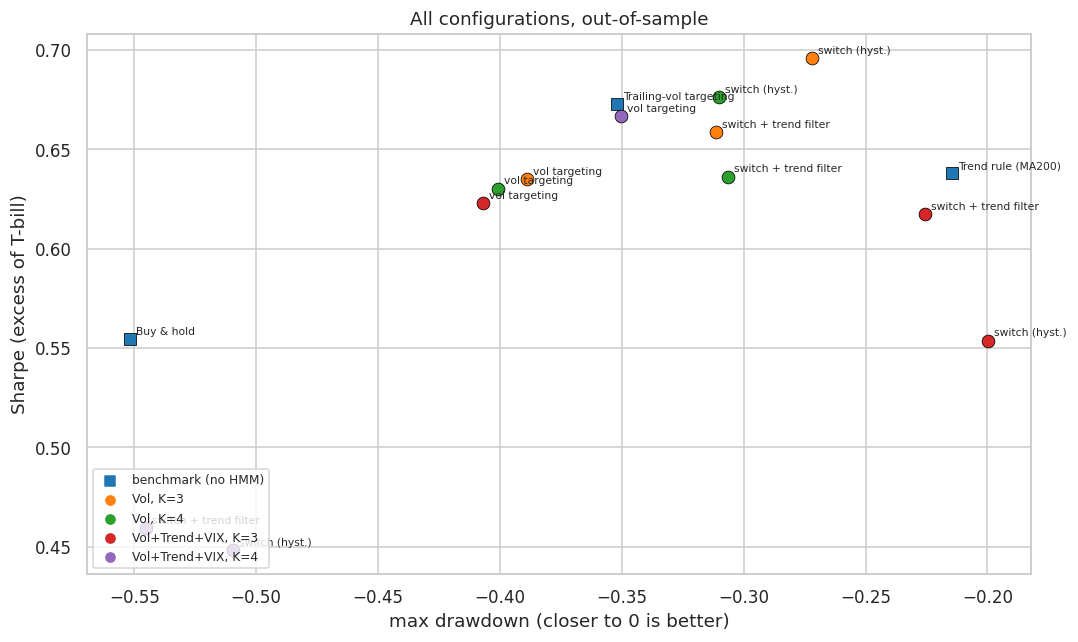

In [47]:
fig, ax = plt.subplots(figsize=(10, 6))
markers = {"benchmark (no HMM)": "s"}
palette = dict(zip(results.index.get_level_values(0).unique(), sns.color_palette("tab10")))
for (cfg, strat), row in results.iterrows():
    ax.scatter(row["max drawdown"], row["Sharpe"], s=70, color=palette[cfg],
               marker=markers.get(cfg, "o"), edgecolor="black", lw=0.5)
    ax.annotate(strat.replace("HMM ", "").replace(" (hysteresis)", " (hyst.)"), (row["max drawdown"], row["Sharpe"]),
                xytext=(4, 3), textcoords="offset points", fontsize=7)
for cfg, color in palette.items():
    ax.scatter([], [], color=color, marker=markers.get(cfg, "o"), label=cfg)
ax.set_xlabel("max drawdown (closer to 0 is better)"); ax.set_ylabel("Sharpe (excess of T-bill)")
ax.set_title("All configurations, out-of-sample"); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(OUT / "02_all_configs.png", bbox_inches="tight"); plt.show()

## 7. The main model in detail

The configuration chosen in advance (`MAIN_CONFIG`) is analysed below. Regime names combine the volatility rank with the sign of
the average trend in that regime (from the most recent refit), which distinguishes, for example, a volatile **downtrend** (crash)
from a volatile **uptrend** (rebound).

Main model: Vol+Trend+VIX, K=4 | filtered regimes, out-of-sample 2007-01-03 to 2026-10-09


,share of test days,expected duration (days),ann. return (same day),ann. vol (same day),next-21d vol,next-21d return,"next-21d return, 5th pct"
regime,,,,,,,
Calm (uptrend),21.6%,77,20.0%,7.8%,9.9%,0.93%,-4.55%
Normal (uptrend),44.3%,71,15.3%,12.6%,13.5%,0.72%,-5.88%
Elevated (downtrend),23.2%,33,-1.8%,27.0%,23.0%,0.09%,-9.95%
Turbulent (downtrend),11.0%,44,15.5%,34.2%,24.6%,2.95%,-9.42%


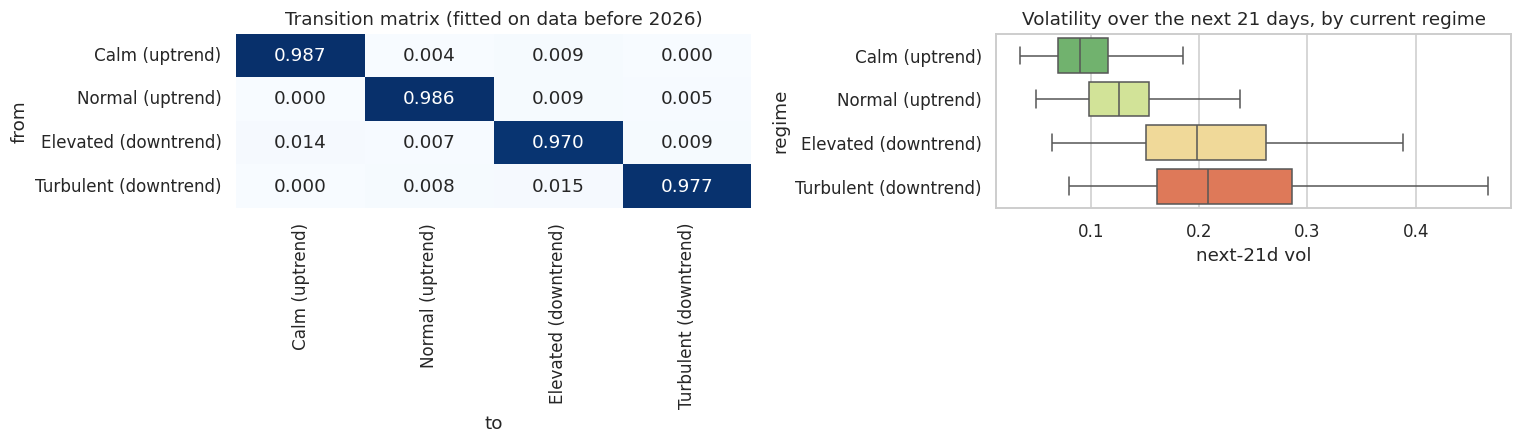

In [48]:
fs_main, K_main = MAIN_CONFIG
main = WF[MAIN_CONFIG]
P_main = main["P"]
last = main["fits"][-1]
m_last, cols_main = last["model"], FEATURE_SETS[fs_main]

def regime_names(model, cols, mu, sd, K):
    names = list(STATE_LABELS[K])
    if "trend" in cols:
        j = cols.index("trend")
        tr = model.means_[:, j] * sd["trend"] + mu["trend"]
        names = [f"{n} ({'up' if t > 0 else 'down'}trend)" for n, t in zip(names, tr)]
    return names

NAMES = regime_names(m_last, cols_main, last["mu"], last["sd"], K_main)
COLORS = sns.color_palette("RdYlGn_r", K_main)
reg = pd.Series(P_main.to_numpy().argmax(axis=1), index=P_main.index)

# out-of-sample description of the filtered regimes
H = 21
fwd_vol = simple_ret.rolling(H).std().shift(-H) * np.sqrt(TRADING_DAYS)
fwd_ret = (np.log(px).shift(-H) - np.log(px)).reindex(data.index)
r_test = simple_ret.reindex(reg.index)
rows = []
for j, name in enumerate(NAMES):
    sel = (reg == j).to_numpy()
    rows.append({"regime": name, "share of test days": sel.mean(),
                 "expected duration (days)": 1 / (1 - m_last.transmat_[j, j]),
                 "ann. return (same day)": r_test[sel].mean() * TRADING_DAYS,
                 "ann. vol (same day)": r_test[sel].std() * np.sqrt(TRADING_DAYS),
                 "next-21d vol": fwd_vol.reindex(reg.index)[sel].mean(),
                 "next-21d return": fwd_ret.reindex(reg.index)[sel].mean(),
                 "next-21d return, 5th pct": fwd_ret.reindex(reg.index)[sel].quantile(0.05)})
regime_table = pd.DataFrame(rows).set_index("regime")
print(f"Main model: {fs_main}, K={K_main} | filtered regimes, out-of-sample {P_main.index[0].date()} to {P_main.index[-1].date()}")
display(regime_table.style.format({"share of test days": "{:.1%}", "expected duration (days)": "{:.0f}",
                                   "ann. return (same day)": "{:.1%}", "ann. vol (same day)": "{:.1%}",
                                   "next-21d vol": "{:.1%}", "next-21d return": "{:.2%}",
                                   "next-21d return, 5th pct": "{:.2%}"}))

if TRUE_REGIME is not None and K_main == 4:
    acc = (reg == TRUE_REGIME.reindex(reg.index)).mean()
    print(f"Synthetic check: filtered regime = true simulated regime on {acc:.1%} of test days")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.heatmap(pd.DataFrame(m_last.transmat_, index=NAMES, columns=NAMES), annot=True, fmt=".3f", cmap="Blues",
            cbar=False, ax=axes[0])
axes[0].set_title(f"Transition matrix (fitted on data before {last['year']})"); axes[0].set_xlabel("to"); axes[0].set_ylabel("from")
fwd = pd.DataFrame({"regime": reg.map(dict(enumerate(NAMES))), "next-21d vol": fwd_vol.reindex(reg.index)}).dropna()
sns.boxplot(data=fwd, y="regime", x="next-21d vol", order=NAMES, palette=COLORS, showfliers=False, ax=axes[1])
axes[1].set_title("Volatility over the next 21 days, by current regime")
plt.tight_layout(); plt.savefig(OUT / "03_regimes_main.png", bbox_inches="tight"); plt.show()

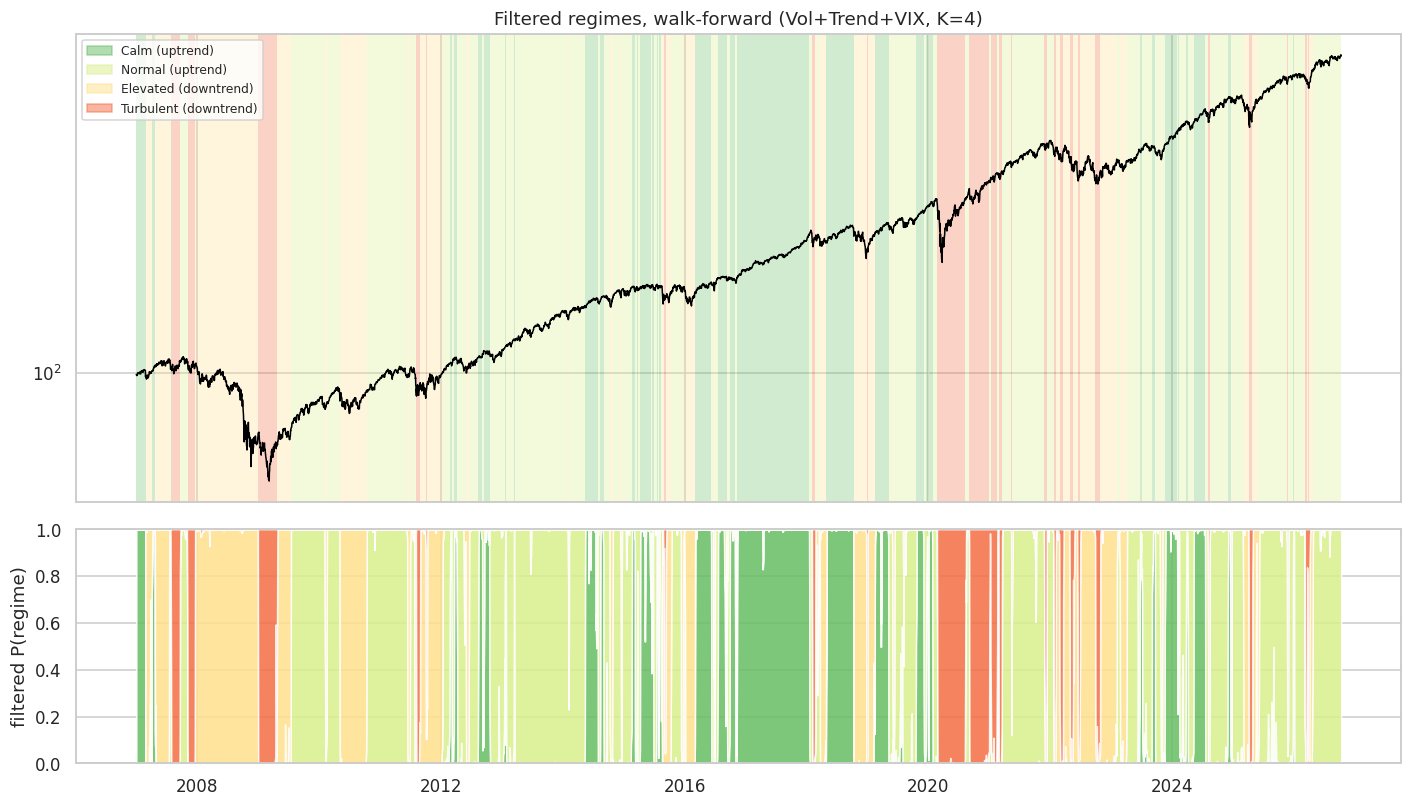

In [49]:
def shade(ax, index, labels, alpha=0.3):
    labels = np.asarray(labels); start = 0
    for i in range(1, len(labels) + 1):
        if i == len(labels) or labels[i] != labels[start]:
            end = index[i] if i < len(labels) else index[-1]
            ax.axvspan(index[start], end, color=COLORS[labels[start]], alpha=alpha, lw=0)
            start = i

from matplotlib.patches import Patch
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(P_main.index, px.reindex(P_main.index), color="black", lw=1); axes[0].set_yscale("log")
shade(axes[0], P_main.index, reg)
axes[0].legend(handles=[Patch(color=COLORS[j], alpha=0.5, label=n) for j, n in enumerate(NAMES)], loc="upper left", fontsize=8)
axes[0].set_title(f"Filtered regimes, walk-forward ({fs_main}, K={K_main})")
axes[1].stackplot(P_main.index, P_main.T.to_numpy(), colors=COLORS, alpha=0.85)
axes[1].set_ylim(0, 1); axes[1].set_ylabel("filtered P(regime)")
plt.tight_layout(); plt.savefig(OUT / "04_regimes_timeline.png", bbox_inches="tight"); plt.show()

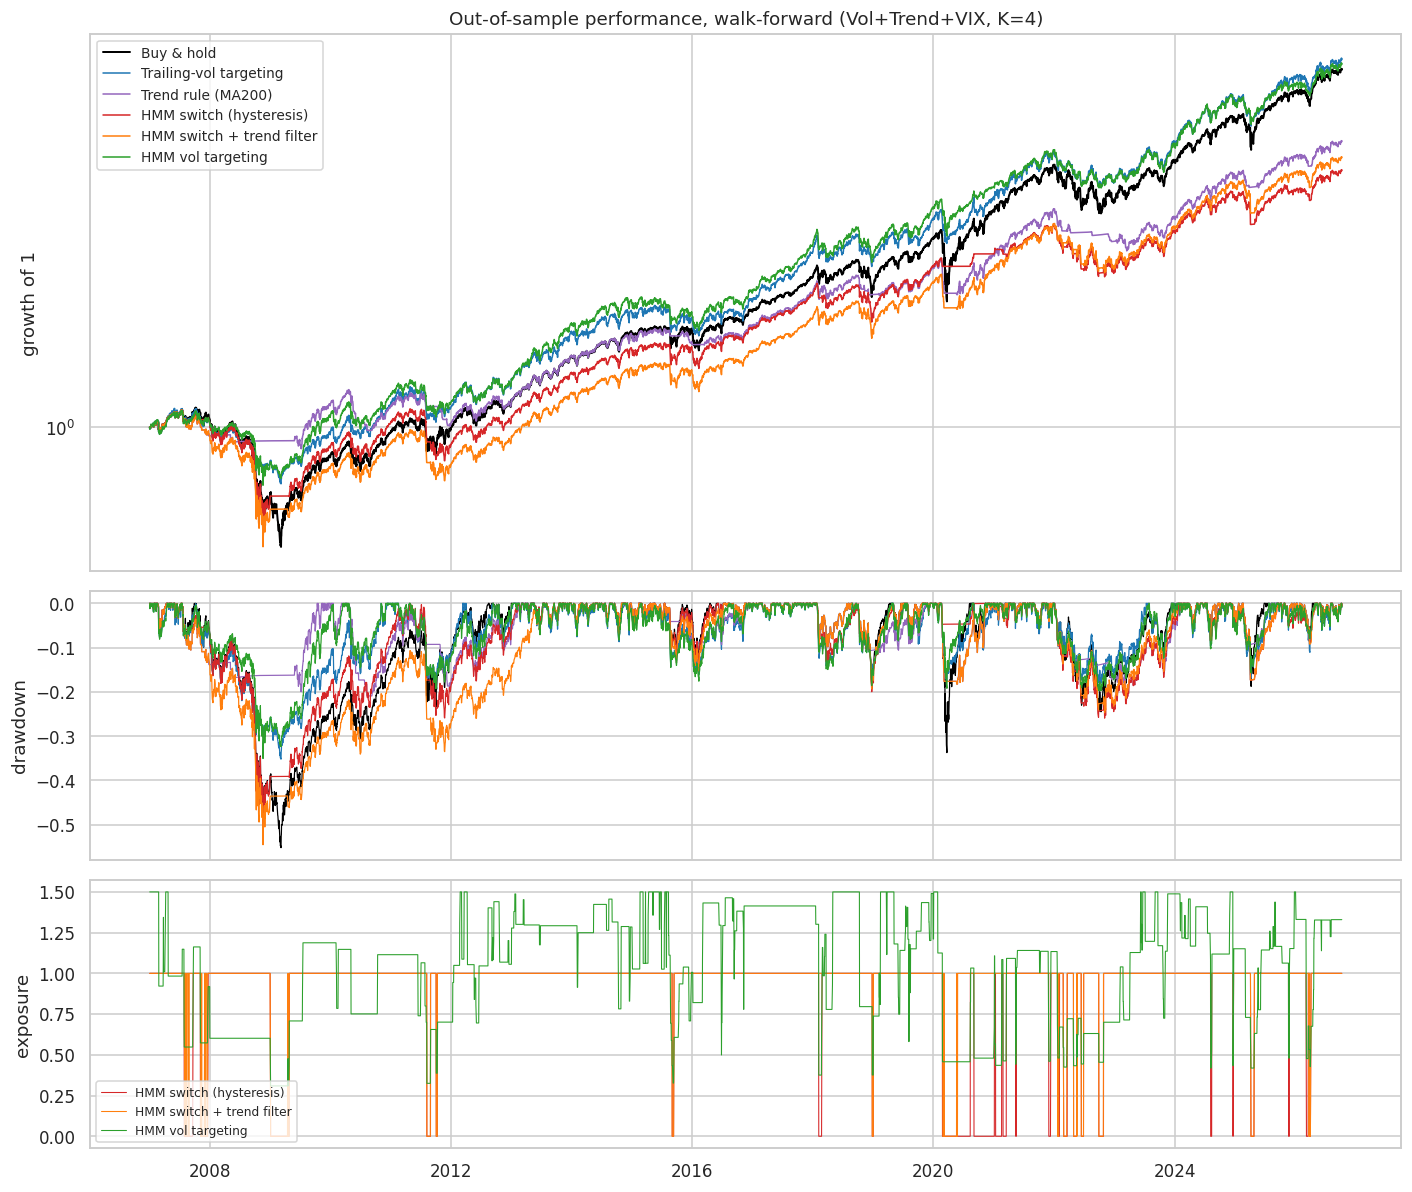

In [50]:
tag = f"{fs_main}, K={K_main}"
show = ["Buy & hold", "Trailing-vol targeting", "Trend rule (MA200)"] + [f"{s} [{tag}]" for s in main["weights"].columns]
colors = ["black", "tab:blue", "tab:purple", "tab:red", "tab:orange", "tab:green"]
eq = (1 + strategy_returns[show]).cumprod()
dd = eq / eq.cummax() - 1

fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
for name, c in zip(show, colors):
    axes[0].plot(eq.index, eq[name], color=c, lw=1.3 if name == "Buy & hold" else 1, label=name.replace(f" [{tag}]", ""))
    axes[1].plot(dd.index, dd[name], color=c, lw=0.8)
axes[0].set_yscale("log"); axes[0].set_ylabel("growth of 1"); axes[0].legend(loc="upper left", fontsize=9)
axes[0].set_title(f"Out-of-sample performance, walk-forward ({tag})")
axes[1].set_ylabel("drawdown")
for name, c in zip(main["weights"].columns, ["tab:red", "tab:orange", "tab:green"]):
    axes[2].plot(EVAL_IDX, main["weights"][name].shift(1).reindex(EVAL_IDX), color=c, lw=0.7, label=name)
axes[2].set_ylabel("exposure"); axes[2].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "05_backtest_main.png", bbox_inches="tight"); plt.show()

## 8. Are the differences statistically significant?

Daily returns are autocorrelated in volatility, so a plain bootstrap would understate uncertainty. A **circular block bootstrap**
(blocks of 21 days, resampled jointly for the two strategies being compared) gives a 95 % confidence interval for the difference
in Sharpe ratio. If the interval contains 0, the data cannot tell the two strategies apart.

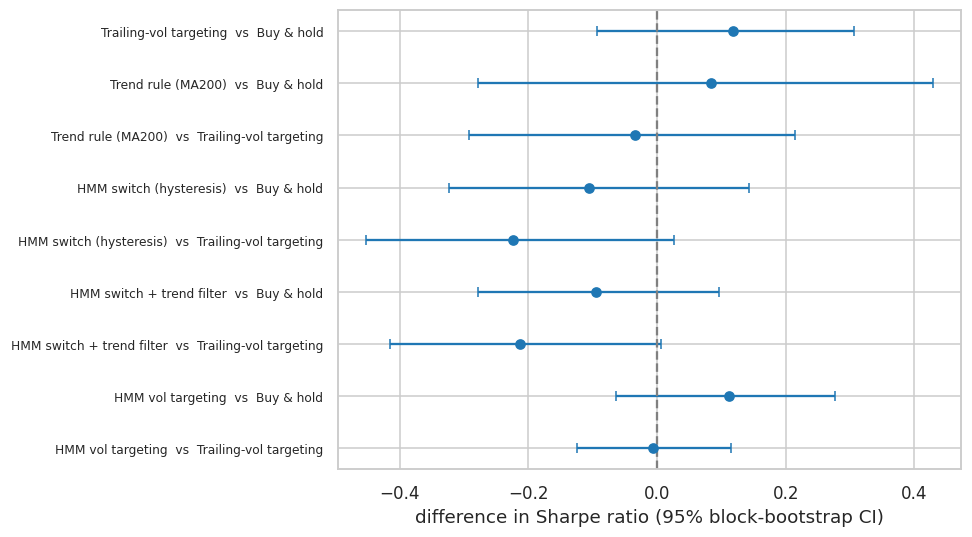

In [51]:
def sharpe_np(x, axis=-1):
    return x.mean(axis) / x.std(axis) * np.sqrt(TRADING_DAYS)

def bootstrap_sharpe_diff(a, b, n_boot=BOOT_N, block=BOOT_BLOCK, seed=SEED, chunk=250):
    a, b = np.asarray(a), np.asarray(b)
    n = len(a); n_blocks = int(np.ceil(n / block))
    rng = np.random.default_rng(seed)
    diffs = []
    for start in range(0, n_boot, chunk):
        m = min(chunk, n_boot - start)
        starts = rng.integers(0, n, size=(m, n_blocks))
        idx = ((starts[:, :, None] + np.arange(block)) % n).reshape(m, -1)[:, :n]
        diffs.append(sharpe_np(a[idx]) - sharpe_np(b[idx]))
    d = np.concatenate(diffs)
    return sharpe_np(a) - sharpe_np(b), np.percentile(d, [2.5, 97.5]), (d <= 0).mean()

ex = strategy_returns.sub(rf_earned.reindex(strategy_returns.index), axis=0)
rows = []
for name in show[1:]:
    for ref in ["Buy & hold", "Trailing-vol targeting"]:
        if name == ref:
            continue
        diff, (lo, hi), p_le0 = bootstrap_sharpe_diff(ex[name], ex[ref])
        rows.append({"strategy": name.replace(f" [{tag}]", ""), "vs": ref, "Sharpe difference": diff,
                     "95% CI low": lo, "95% CI high": hi, "share of resamples <= 0": p_le0,
                     "significant": "yes" if lo > 0 or hi < 0 else "no"})
sig = pd.DataFrame(rows).set_index(["strategy", "vs"])
display(sig.style.format({"Sharpe difference": "{:+.2f}", "95% CI low": "{:+.2f}", "95% CI high": "{:+.2f}",
                          "share of resamples <= 0": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(9, 0.45 * len(sig) + 1))
y = np.arange(len(sig))
ax.errorbar(sig["Sharpe difference"], y, xerr=[sig["Sharpe difference"] - sig["95% CI low"],
                                               sig["95% CI high"] - sig["Sharpe difference"]],
            fmt="o", color="tab:blue", capsize=3)
ax.axvline(0, color="gray", ls="--")
ax.set_yticks(y); ax.set_yticklabels([f"{s}  vs  {v}" for s, v in sig.index], fontsize=8)
ax.set_xlabel("difference in Sharpe ratio (95% block-bootstrap CI)"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(OUT / "06_sharpe_ci.png", bbox_inches="tight"); plt.show()

## 9. Crisis episodes

Total return during the main sell-offs and the rebounds that followed (approximate peak and trough dates of the S&P 500).
Regime strategies should lose less in the crashes; the question is how much of the rebound they miss.

In [52]:
EPISODES = {
    "2008 crisis (Oct 2007 - Mar 2009)": ("2007-10-10", "2009-03-09"),
    "2009 rebound (Mar - Dec 2009)":     ("2009-03-10", "2009-12-31"),
    "COVID crash (Feb - Mar 2020)":      ("2020-02-20", "2020-03-23"),
    "COVID rebound (Mar - Aug 2020)":    ("2020-03-24", "2020-08-18"),
    "2022 bear market (Jan - Oct 2022)": ("2022-01-04", "2022-10-12"),
    "2025 sell-off (Feb - Apr 2025)":    ("2025-02-20", "2025-04-08"),
}
rows = {}
for label, (s, e) in EPISODES.items():
    window = strategy_returns.loc[s:e, show]
    if len(window) > 5:
        rows[label] = (1 + window).prod() - 1
episodes = pd.DataFrame(rows).T
episodes.columns = [c.replace(f" [{tag}]", "") for c in episodes.columns]
if len(episodes):
    display(episodes.style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None))
else:
    print("None of the episodes fall inside this data sample (synthetic data uses its own calendar).")

,Buy & hold,Trailing-vol targeting,Trend rule (MA200),HMM switch (hysteresis),HMM switch + trend filter,HMM vol targeting
2008 crisis (Oct 2007 - Mar 2009),-55.2%,-35.1%,-13.2%,-37.4%,-41.4%,-32.1%
2009 rebound (Mar - Dec 2009),67.4%,32.6%,22.3%,31.8%,26.2%,42.0%
COVID crash (Feb - Mar 2020),-33.7%,-17.8%,-17.6%,-4.7%,-17.6%,-19.2%
COVID rebound (Mar - Aug 2020),52.6%,20.4%,12.8%,1.7%,12.8%,22.5%
2022 bear market (Jan - Oct 2022),-24.5%,-18.1%,-13.8%,-24.2%,-22.6%,-19.7%
2025 sell-off (Feb - Apr 2025),-18.8%,-16.6%,-9.3%,-17.3%,-17.3%,-14.7%


## 10. Sensitivity to transaction costs

In [53]:
cost_rows = []
for c in [0, 5, 10, 25]:
    _, sb = evaluate(benchmark_weights, cost_bps=c)
    _, sm = evaluate(main["weights"], cost_bps=c)
    for name, row in pd.concat([sb, sm]).iterrows():
        cost_rows.append({"strategy": name, "cost (bps)": c, "Sharpe": row["Sharpe"], "CAGR": row["CAGR"]})
cost_table = pd.DataFrame(cost_rows).pivot(index="strategy", columns="cost (bps)", values=["Sharpe", "CAGR"])
display(cost_table.style.format("{:.2f}", subset=["Sharpe"]).format("{:.2%}", subset=["CAGR"]))

## 11. Summary and export

In [54]:
bh = results.loc[("benchmark (no HMM)", "Buy & hold")]
tv = results.loc[("benchmark (no HMM)", "Trailing-vol targeting")]
hmm_rows = results.drop(index="benchmark (no HMM)", level=0)
best_hmm = hmm_rows["Sharpe"].idxmax()
best_dd = hmm_rows["max drawdown"].idxmax()

print(f"Data: {TICKER} ({source}); out-of-sample {EVAL_IDX[0].date()} to {EVAL_IDX[-1].date()}, "
      f"walk-forward refit every {REFIT_EVERY_YEARS} year(s)")
print(f"Buy & hold              : Sharpe {bh['Sharpe']:.2f} | CAGR {bh['CAGR']:.2%} | max DD {bh['max drawdown']:.1%}")
print(f"Trailing-vol targeting  : Sharpe {tv['Sharpe']:.2f} | CAGR {tv['CAGR']:.2%} | max DD {tv['max drawdown']:.1%}")
r = results.loc[best_hmm]
print(f"Best HMM Sharpe         : {best_hmm[1]} [{best_hmm[0]}] Sharpe {r['Sharpe']:.2f} | CAGR {r['CAGR']:.2%} | "
      f"max DD {r['max drawdown']:.1%}")
r = results.loc[best_dd]
print(f"Smallest HMM drawdown   : {best_dd[1]} [{best_dd[0]}] max DD {r['max drawdown']:.1%} "
      f"(same-exposure constant mix: {r['same-exposure max DD']:.1%})")
n_sig = (sig["significant"] == "yes").sum()
print(f"Sharpe differences significant at 95% (main model): {n_sig} of {len(sig)} comparisons")

results.to_csv(OUT / "results_all_configs.csv")
sig.to_csv(OUT / "sharpe_bootstrap.csv")
regime_table.to_csv(OUT / "regimes_main.csv")
episodes.to_csv(OUT / "crisis_episodes.csv")
P_main.to_csv(OUT / "filtered_probabilities_main.csv")
bic_table.to_csv(OUT / "bic.csv")
print(f"\nFigures and tables saved in {OUT.resolve()}")

Data: SPY (Yahoo Finance); out-of-sample 2007-01-04 to 2026-10-09, walk-forward refit every 1 year(s)
Buy & hold              : Sharpe 0.55 | CAGR 11.03% | max DD -55.2%
Trailing-vol targeting  : Sharpe 0.67 | CAGR 11.38% | max DD -35.2%
Best HMM Sharpe         : HMM switch (hysteresis) [Vol, K=3] Sharpe 0.70 | CAGR 9.74% | max DD -27.2%
Smallest HMM drawdown   : HMM switch (hysteresis) [Vol+Trend+VIX, K=3] max DD -20.0% (same-exposure constant mix: -41.8%)
Sharpe differences significant at 95% (main model): 0 of 9 comparisons

Figures and tables saved in /kaggle/working/outputs
